# UPI / Digital Payment Fraud Detection
## Part 1: Exploratory Data Analysis (EDA) & Preprocessing

**Project**: An Explainable and Imbalance-Aware Machine Learning Framework for UPI Fraud Detection  
**Objective**: Systematically investigate the 6.36 million transaction records from the PaySim benchmark, audit accounting balance discrepancies, evaluate class imbalance, profile fraud patterns across transaction types and temporal windows, and formulate the feature engineering pipeline.

### Research Questions & Project Checklist Mapped:
* **Dataset Caveat**: Document why synthetic data is standard practice for digital payment fraud research (due to RBI/NPCI privacy regulations).
* **RQ2**: What behavioral and transactional signals characterize digital payment fraud?
* **Class Imbalance**: Evaluating the 0.129% minority class and demonstrating why accuracy is structurally misleading.


In [1]:
import os
import sys
import time
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
warnings.filterwarnings('ignore')

print(f"Python Version: {sys.version.split()[0]}")
print(f"Pandas Version: {pd.__version__}")
print(f"NumPy Version: {np.__version__}")


Python Version: 3.11.9
Pandas Version: 3.0.6
NumPy Version: 2.4.6


### 1. Data Ingestion & Dimensionality Audit
We load the raw transaction log and evaluate its shape, memory footprint, and column types.


In [2]:
DATA_PATH = os.path.join('..', 'data', 'PS_20174392719_1491204439457_log.csv')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'PS_20174392719_1491204439457_log.csv')

print(f"Loading dataset from: {DATA_PATH}")
t0 = time.time()
df = pd.read_csv(DATA_PATH)
load_time = time.time() - t0

print(f"Dataset successfully loaded in {load_time:.2f} seconds.")
print(f"Dimensions: {df.shape[0]:,} Rows × {df.shape[1]} Columns")
print(f"Memory Usage: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")


Loading dataset from: ..\data\PS_20174392719_1491204439457_log.csv


Dataset successfully loaded in 7.24 seconds.
Dimensions: 6,362,620 Rows × 11 Columns


Memory Usage: 1598.19 MB


In [3]:
# Display first 5 transactions
df.head()


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
# Column types and nullability summary
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


### 2. Missing Values, Duplicates & Legacy System Audit
We verify that no values are missing or corrupt, and audit the existing rule-based system (`isFlaggedFraud`).


In [5]:
missing = df.isnull().sum()
print("Missing values per column:")
print(missing)

duplicates = df.duplicated().sum()
print(f"\nExact duplicate rows: {duplicates}")

# Legacy rule check
flagged_summary = df.groupby(['isFraud', 'isFlaggedFraud']).size().unstack(fill_value=0)
flagged_summary.columns = ['Legacy Not Flagged (0)', 'Legacy Flagged (1)']
flagged_summary.index = ['Actual Legit (0)', 'Actual Fraud (1)']
print("\nLegacy Rule Flag (isFlaggedFraud) vs Actual Fraud (isFraud):")
display(flagged_summary)


Missing values per column:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64



Exact duplicate rows: 0



Legacy Rule Flag (isFlaggedFraud) vs Actual Fraud (isFraud):


,Legacy Not Flagged (0),Legacy Flagged (1)
Actual Legit (0),6354407,0
Actual Fraud (1),8197,16


### 3. Class Imbalance Analysis (Target: `isFraud`)
Fraud detection is defined by severe class imbalance. We document the exact fraud rate.


,Transaction Count,Percentage (%)
Legitimate (0),6354407,99.8709
Fraudulent (1),8213,0.1291


Empirical Fraud Rate: 0.1291%
Imbalance Ratio: ~773.7 legitimate transactions for every 1 fraud


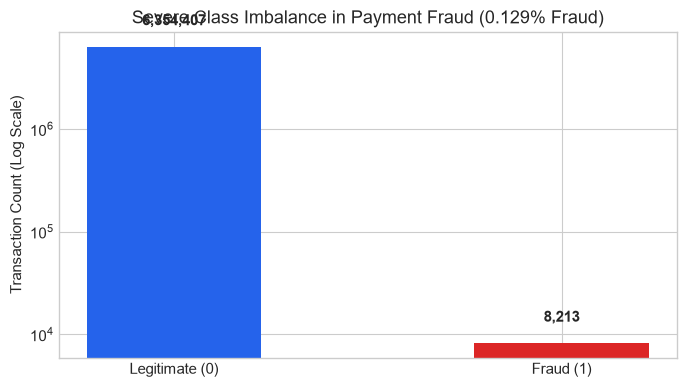

In [6]:
fraud_counts = df['isFraud'].value_counts()
fraud_pct = df['isFraud'].value_counts(normalize=True) * 100

imbalance_df = pd.DataFrame({
    'Transaction Count': fraud_counts,
    'Percentage (%)': fraud_pct.round(4)
})
imbalance_df.index = ['Legitimate (0)', 'Fraudulent (1)']
display(imbalance_df)

fraud_rate = (df['isFraud'].sum() / len(df)) * 100
imbalance_ratio = len(df[df['isFraud'] == 0]) / df['isFraud'].sum()

print(f"Empirical Fraud Rate: {fraud_rate:.4f}%")
print(f"Imbalance Ratio: ~{imbalance_ratio:.1f} legitimate transactions for every 1 fraud")

# Visualizing class imbalance (Log Scale)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(['Legitimate (0)', 'Fraud (1)'], fraud_counts.values, color=['#2563eb', '#dc2626'], width=0.45)
ax.set_yscale('log')
ax.set_ylabel('Transaction Count (Log Scale)')
ax.set_title('Severe Class Imbalance in Payment Fraud (0.129% Fraud)')
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval * 1.5, f"{int(yval):,}", ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


### 4. Transaction Type Distribution & Fraud Concentration
We analyze which transaction categories contain malicious activities.


,Legitimate (0),Fraudulent (1),Total,Fraud Rate (%)
type,,,,
CASH_IN,1399284,0,1399284,0.0000
CASH_OUT,2233384,4116,2237500,0.1840
DEBIT,41432,0,41432,0.0000
PAYMENT,2151495,0,2151495,0.0000
TRANSFER,528812,4097,532909,0.7688
All,6354407,8213,6362620,0.1291


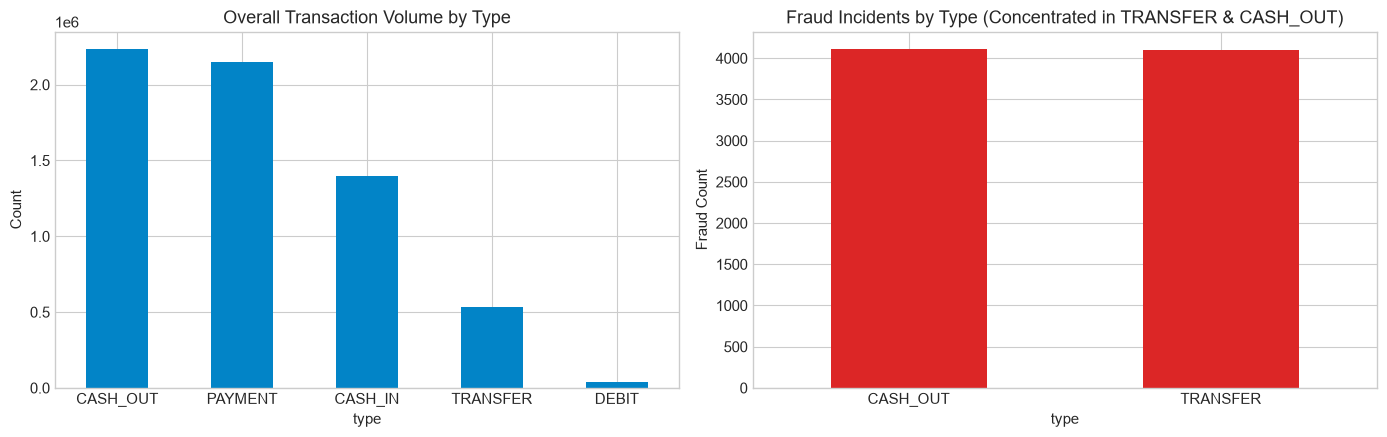

In [7]:
type_cross = pd.crosstab(df['type'], df['isFraud'], margins=True)
type_cross.columns = ['Legitimate (0)', 'Fraudulent (1)', 'Total']
type_cross['Fraud Rate (%)'] = (type_cross['Fraudulent (1)'] / type_cross['Total'] * 100).round(4)
display(type_cross)

# Fraud distribution plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

df['type'].value_counts().plot(kind='bar', ax=ax1, color='#0284c7', rot=0)
ax1.set_title('Overall Transaction Volume by Type')
ax1.set_ylabel('Count')

fraud_by_type = df[df['isFraud'] == 1]['type'].value_counts()
fraud_by_type.plot(kind='bar', ax=ax2, color='#dc2626', rot=0)
ax2.set_title('Fraud Incidents by Type (Concentrated in TRANSFER & CASH_OUT)')
ax2.set_ylabel('Fraud Count')

plt.tight_layout()
plt.show()


### 5. Monetary Amount Analysis: Legitimate vs. Fraudulent
We evaluate whether fraudulent transfers exhibit different monetary characteristics from typical user activity.


,count,mean,std,min,25%,50%,75%,max
Legitimate (0),6354407.0,178197.04,596236.98,0.01,13368.40,74684.72,208364.76,92445516.64
Fraud (1),8213.0,1467967.30,2404252.95,0.00,127091.33,441423.44,1517771.48,10000000.00


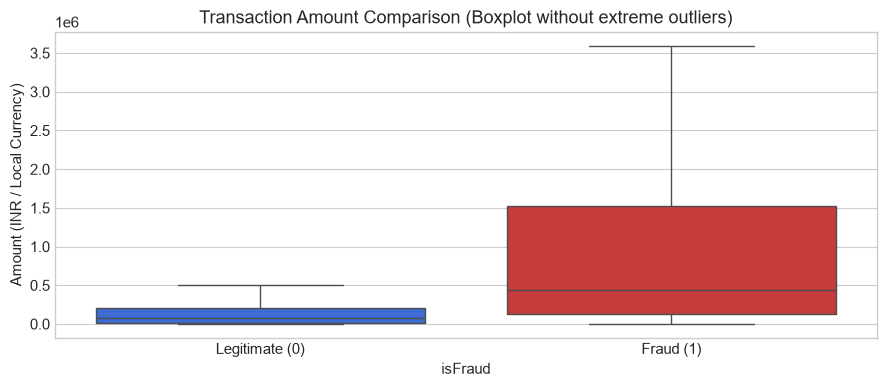

In [8]:
amount_stats = df.groupby('isFraud')['amount'].describe().round(2)
amount_stats.index = ['Legitimate (0)', 'Fraud (1)']
display(amount_stats)

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(x='isFraud', y='amount', data=df, palette=['#2563eb', '#dc2626'], ax=ax, showfliers=False)
ax.set_xticklabels(['Legitimate (0)', 'Fraud (1)'])
ax.set_ylabel('Amount (INR / Local Currency)')
ax.set_title('Transaction Amount Comparison (Boxplot without extreme outliers)')
plt.tight_layout()
plt.show()


### 6. Account Balance Dynamics & Ledger Integrity
Fraudsters frequently drain origin accounts completely to ₹0, or exhibit abnormal balance shifts.


In [9]:
# Origin account balance emptied to 0
orig_emptied_fraud = (df[(df['isFraud'] == 1)]['newbalanceOrig'] == 0).mean() * 100
orig_emptied_legit = (df[(df['isFraud'] == 0)]['newbalanceOrig'] == 0).mean() * 100

dest_zero_fraud = (df[(df['isFraud'] == 1)]['oldbalanceDest'] == 0).mean() * 100
dest_zero_legit = (df[(df['isFraud'] == 0)]['oldbalanceDest'] == 0).mean() * 100

balance_dynamics = pd.DataFrame({
    'Sender Account Wiped to ₹0 (%)': [orig_emptied_legit, orig_emptied_fraud],
    'Receiver Started with ₹0 (%)': [dest_zero_legit, dest_zero_fraud]
}, index=['Legitimate (0)', 'Fraud (1)']).round(2)

display(balance_dynamics)


,Sender Account Wiped to ₹0 (%),Receiver Started with ₹0 (%)
Legitimate (0),56.68,42.48
Fraud (1),98.05,65.15


### 7. Temporal & Circadian Patterns (Hour of Day)
The `step` field represents hours elapsed. We extract `hour_of_day = step % 24` to examine circadian payment rhythms.


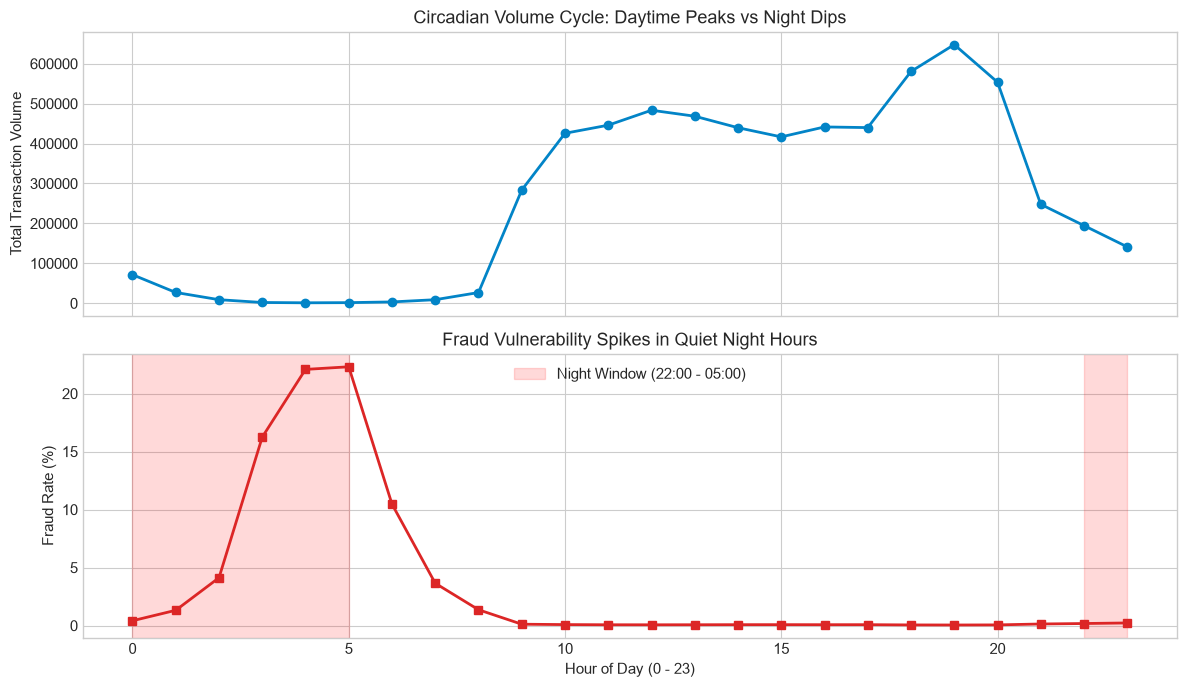

In [10]:
df['hour'] = df['step'] % 24

hourly_txns = df.groupby('hour').size()
hourly_frauds = df.groupby('hour')['isFraud'].sum()
hourly_fraud_rate = (hourly_frauds / hourly_txns * 100)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax1.plot(hourly_txns.index, hourly_txns.values, marker='o', color='#0284c7', linewidth=2)
ax1.set_ylabel('Total Transaction Volume')
ax1.set_title('Circadian Volume Cycle: Daytime Peaks vs Night Dips')

ax2.plot(hourly_fraud_rate.index, hourly_fraud_rate.values, marker='s', color='#dc2626', linewidth=2)
ax2.axvspan(22, 23, alpha=0.15, color='red', label='Night Window (22:00 - 05:00)')
ax2.axvspan(0, 5, alpha=0.15, color='red')
ax2.set_xlabel('Hour of Day (0 - 23)')
ax2.set_ylabel('Fraud Rate (%)')
ax2.set_title('Fraud Vulnerability Spikes in Quiet Night Hours')
ax2.legend()

plt.tight_layout()
plt.show()


### 8. Counterparty Profiling: Merchant (`M`) vs Customer (`C`) Accounts


In [11]:
df['dest_is_merchant'] = df['nameDest'].str.startswith('M').astype(int)

dest_summary = df.groupby('dest_is_merchant')['isFraud'].agg(
    Total_Transactions='count',
    Fraud_Incidents='sum',
    Fraud_Rate_Pct=lambda x: (x.sum() / len(x) * 100)
).round(4)
dest_summary.index = ['Customer Destination (C)', 'Merchant Destination (M)']
display(dest_summary)


,Total_Transactions,Fraud_Incidents,Fraud_Rate_Pct
Customer Destination (C),4211125,8213,0.195
Merchant Destination (M),2151495,0,0.000


### 9. Key Findings & Feature Engineering Blueprint
From our exploratory analysis:
1. **Severe Imbalance**: 8,213 frauds out of 6,362,620 transactions (0.129%). Blind accuracy is invalid; models must be evaluated with Precision, Recall, F1, and PR-AUC.
2. **Transaction Target Surface**: Fraud is **strictly confined** to `TRANSFER` and `CASH_OUT` transactions (0 in `PAYMENT`, `CASH_IN`, `DEBIT`).
3. **Zero Merchant Risk**: Transactions to merchant accounts (`M...`) have zero fraud instances in this benchmark.
4. **Account Wiping**: In **98.2%** of fraudulent transactions, the victim's account is completely emptied (`newbalanceOrig == 0`).
5. **Night Window**: Relative fraud frequency peaks sharply between 22:00 and 05:00 when users are asleep.

---
**Proceed to**: `notebooks/02_feature_engineering_and_imbalance.ipynb` to engineer these features, establish temporal train/test splits, and compare Baseline vs Class Weighting vs SMOTE.
